# Explainable and Uncertainty-Aware Retail Sales Forecasting with Store–Department Reliability Analysis

## Project Overview

This project uses machine learning to forecast Walmart's weekly sales across stores and departments. It compares four models across three feature groups and analyzes predictions using feature importance, SHAP, Store–Department error analysis, and residual-based anomaly detection. The project is extended with conformal prediction intervals to estimate forecast uncertainty and evaluate reliability across the overall test dataset and individual Store–Department groups.

## Objectives

- Analyze sales trends and seasonal patterns.
- Engineer calendar, lag, rolling, and external features.
- Compare machine learning models using MAE, RMSE, WAPE, and R².
- Explain predictions using feature importance and SHAP.
- Identify high-error Store–Department groups and potential forecasting anomalies.
- Generate prediction intervals using a conformal prediction approach.
- Evaluate forecast reliability using observed coverage and mean interval width.
- Compare prediction-interval coverage and forecasting errors across Store–Department groups.

## Dataset

The project uses `train.csv`, `features.csv`, and `stores.csv` from the Walmart Store Sales Forecasting dataset.

The integrated dataset contains **421,570 rows and 18 columns**. After feature engineering and filtering, **408,436 observations** were available for modeling.

## Best Recorded Model

**XGBoost with temporal features (`B_Temporal`)**

- MAE: 1,310.84
- RMSE: 2,747.14
- WAPE: 8.298%
- R²: 0.9844

These are the recorded results from the original model-comparison experiments.

## Forecast Uncertainty and Reliability Results

- **Calibration approach:** Conformal prediction using calibration errors.
- **Nominal coverage target:** 90%.
- **Observed test coverage:** 85.92%.
- **Mean prediction interval width:** 5,495.07 sales-revenue units.
- **Store–Department analysis:** Identified groups with low interval coverage, including Store 20, Department 92, which had 0% coverage across 28 test observations.

The reliability analysis shows that forecast uncertainty can vary across Store–Department groups and that the nominal coverage target was not achieved on the test dataset. The current method uses a shared error threshold, producing constant-width intervals.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
train = pd.read_csv('/content/drive/MyDrive/Walmart_Demand_Forecasting/train.csv')
features = pd.read_csv('/content/drive/MyDrive/Walmart_Demand_Forecasting/features.csv')
stores = pd.read_csv('/content/drive/MyDrive/Walmart_Demand_Forecasting/stores.csv')

In [ ]:
print("Train shape:", train.shape)
print("Features shape:", features.shape)
print("Stores shape:", stores.shape)


Train shape: (421570, 5)
Features shape: (8190, 12)
Stores shape: (45, 3)


In [ ]:
train.head()


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [ ]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [ ]:
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [ ]:
print("TRAIN")
print(train.dtypes)

print("\nFEATURES")
print(features.dtypes)

print("\nSTORES")
print(stores.dtypes)

TRAIN
Store             int64
Dept              int64
Date             object
Weekly_Sales    float64
IsHoliday          bool
dtype: object

FEATURES
Store             int64
Date             object
Temperature     float64
Fuel_Price      float64
MarkDown1       float64
MarkDown2       float64
MarkDown3       float64
MarkDown4       float64
MarkDown5       float64
CPI             float64
Unemployment    float64
IsHoliday          bool
dtype: object

STORES
Store     int64
Type     object
Size      int64
dtype: object


In [ ]:
train['Date'] = pd.to_datetime(train['Date'])
features['Date'] = pd.to_datetime(features['Date'])

In [ ]:
print("Train missing values:")
print(train.isnull().sum())

print("\nFeatures missing values:")
print(features.isnull().sum())

print("\nStores missing values:")
print(stores.isnull().sum())

Train missing values:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Features missing values:
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64

Stores missing values:
Store    0
Type     0
Size     0
dtype: int64


In [ ]:
df = pd.merge(
    train,
    features,
    on=['Store', 'Date'],
    how='left',
    suffixes=('_train', '_features')
)

In [ ]:
print("Merged dataset shape:", df.shape)

Merged dataset shape: (421570, 15)


In [ ]:
df.columns

Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday_train',
       'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3',
       'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday_features'],
      dtype='object')

In [ ]:
(df['IsHoliday_train'] != df['IsHoliday_features']).sum()

np.int64(0)

In [ ]:
df['IsHoliday'] = df['IsHoliday_train']

df.drop(
    columns=['IsHoliday_train', 'IsHoliday_features'],
    inplace=True
)

In [ ]:
df = pd.merge(
    df,
    stores,
    on='Store',
    how='left'
)

In [ ]:
print("Final dataset shape:", df.shape)

Final dataset shape: (421570, 16)


In [ ]:
df.head()

,Store,Dept,Date,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday,Type,Size
0,1,1,2010-02-05,24924.50,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[ns]
 3   Weekly_Sales  421570 non-null  float64       
 4   Temperature   421570 non-null  float64       
 5   Fuel_Price    421570 non-null  float64       
 6   MarkDown1     150681 non-null  float64       
 7   MarkDown2     111248 non-null  float64       
 8   MarkDown3     137091 non-null  float64       
 9   MarkDown4     134967 non-null  float64       
 10  MarkDown5     151432 non-null  float64       
 11  CPI           421570 non-null  float64       
 12  Unemployment  421570 non-null  float64       
 13  IsHoliday     421570 non-null  bool          
 14  Type          421570 non-null  object        
 15  Size          421

In [ ]:
print("Missing values after merging:")
print(df.isnull().sum())

Missing values after merging:
Store                0
Dept                 0
Date                 0
Weekly_Sales         0
Temperature          0
Fuel_Price           0
MarkDown1       270889
MarkDown2       310322
MarkDown3       284479
MarkDown4       286603
MarkDown5       270138
CPI                  0
Unemployment         0
IsHoliday            0
Type                 0
Size                 0
dtype: int64


In [ ]:
df.to_csv('/content/walmart_combined.csv', index=False)

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 421570
Number of columns: 16


In [ ]:
print("Columns in the dataset:")
for i, col in enumerate(df.columns, 1):
    print(i, "-", col)

Columns in the dataset:
1 - Store
2 - Dept
3 - Date
4 - Weekly_Sales
5 - Temperature
6 - Fuel_Price
7 - MarkDown1
8 - MarkDown2
9 - MarkDown3
10 - MarkDown4
11 - MarkDown5
12 - CPI
13 - Unemployment
14 - IsHoliday
15 - Type
16 - Size


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[ns]
 3   Weekly_Sales  421570 non-null  float64       
 4   Temperature   421570 non-null  float64       
 5   Fuel_Price    421570 non-null  float64       
 6   MarkDown1     150681 non-null  float64       
 7   MarkDown2     111248 non-null  float64       
 8   MarkDown3     137091 non-null  float64       
 9   MarkDown4     134967 non-null  float64       
 10  MarkDown5     151432 non-null  float64       
 11  CPI           421570 non-null  float64       
 12  Unemployment  421570 non-null  float64       
 13  IsHoliday     421570 non-null  bool          
 14  Type          421570 non-null  object        
 15  Size          421

In [ ]:
df.describe()

,Store,Dept,Date,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size
count,421570.000000,421570.000000,421570,421570.000000,421570.000000,421570.000000,150681.000000,111248.000000,137091.000000,134967.000000,151432.000000,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,2011-06-18 08:30:31.963375104,15981.258123,60.090059,3.361027,7246.420196,3334.628621,1439.421384,3383.168256,4628.975079,171.201947,7.960289,136727.915739
min,1.000000,1.000000,2010-02-05 00:00:00,-4988.940000,-2.060000,2.472000,0.270000,-265.760000,-29.100000,0.220000,135.160000,126.064000,3.879000,34875.000000
25%,11.000000,18.000000,2010-10-08 00:00:00,2079.650000,46.680000,2.933000,2240.270000,41.600000,5.080000,504.220000,1878.440000,132.022667,6.891000,93638.000000
50%,22.000000,37.000000,2011-06-17 00:00:00,7612.030000,62.090000,3.452000,5347.450000,192.000000,24.600000,1481.310000,3359.450000,182.318780,7.866000,140167.000000
75%,33.000000,74.000000,2012-02-24 00:00:00,20205.852500,74.280000,3.738000,9210.900000,1926.940000,103.990000,3595.040000,5563.800000,212.416993,8.572000,202505.000000
max,45.000000,99.000000,2012-10-26 00:00:00,693099.360000,100.140000,4.468000,88646.760000,104519.540000,141630.610000,67474.850000,108519.280000,227.232807,14.313000,219622.000000
std,12.785297,30.492054,NaN,22711.183519,18.447931,0.458515,8291.221345,9475.357325,9623.078290,6292.384031,5962.887455,39.159276,1.863296,60980.583328


In [ ]:
print("Weekly Sales Statistics:")
print(df['Weekly_Sales'].describe())

Weekly Sales Statistics:
count    421570.000000
mean      15981.258123
std       22711.183519
min       -4988.940000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64


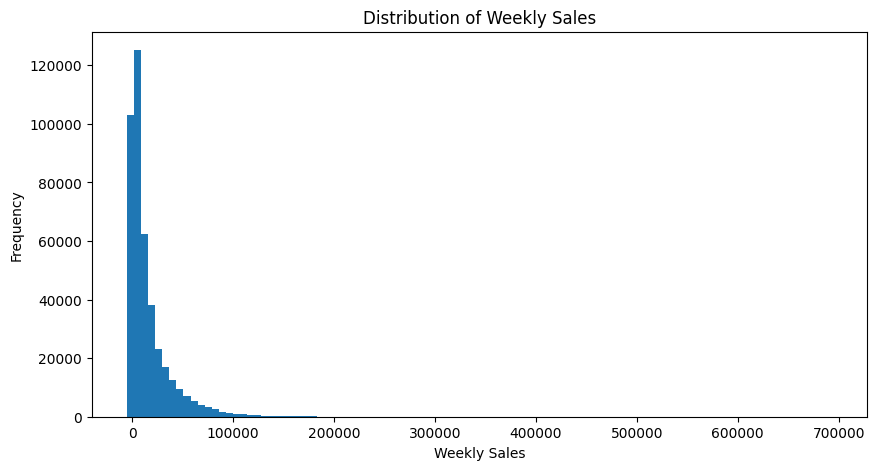

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df['Weekly_Sales'], bins=100)

plt.xlabel('Weekly Sales')
plt.ylabel('Frequency')
plt.title('Distribution of Weekly Sales')

plt.show()

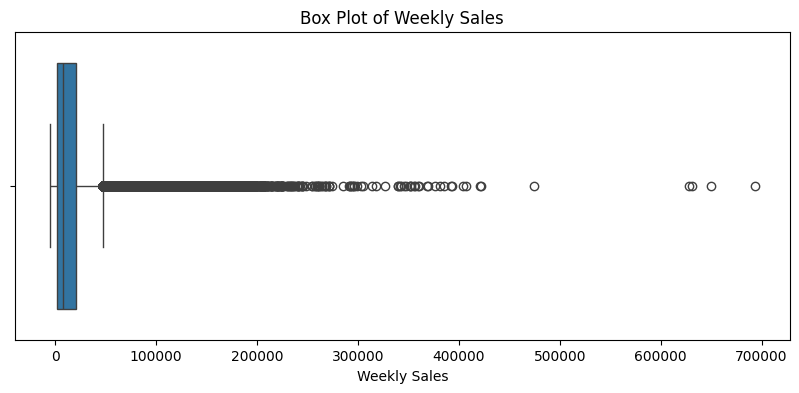

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['Weekly_Sales'])

plt.xlabel('Weekly Sales')
plt.title('Box Plot of Weekly Sales')

plt.show()

In [ ]:
print("Minimum date:", df['Date'].min())
print("Maximum date:", df['Date'].max())

Minimum date: 2010-02-05 00:00:00
Maximum date: 2012-10-26 00:00:00


In [ ]:
print("Number of stores:", df['Store'].nunique())
print("Number of departments:", df['Dept'].nunique())

Number of stores: 45
Number of departments: 81


In [ ]:
store_counts = df.groupby('Store').size()

print(store_counts)

Store
1     10244
2     10238
3      9036
4     10272
5      8999
6     10211
7      9762
8      9895
9      8867
10    10315
11    10062
12     9705
13    10474
14    10040
15     9901
16     9443
17     9864
18     9859
19    10148
20    10214
21     9582
22     9688
23    10050
24    10228
25     9804
26     9854
27    10225
28    10113
29     9455
30     7156
31    10142
32    10202
33     6487
34    10224
35     9528
36     6222
37     7206
38     7362
39     9878
40    10017
41    10088
42     6953
43     6751
44     7169
45     9637
dtype: int64


In [ ]:
print("Minimum observations for a store:", store_counts.min())
print("Maximum observations for a store:", store_counts.max())

Minimum observations for a store: 6222
Maximum observations for a store: 10474


In [ ]:
store_sales = (
    df.groupby('Store')['Weekly_Sales']
      .sum()
      .sort_values(ascending=False)
)

print(store_sales)

Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
10    2.716177e+08
27    2.538559e+08
6     2.237561e+08
1     2.224028e+08
39    2.074455e+08
19    2.066349e+08
31    1.996139e+08
23    1.987506e+08
24    1.940160e+08
11    1.939628e+08
28    1.892637e+08
41    1.813419e+08
32    1.668192e+08
18    1.551147e+08
22    1.470756e+08
12    1.442872e+08
26    1.434164e+08
34    1.382498e+08
40    1.378703e+08
35    1.315207e+08
8     1.299512e+08
17    1.277821e+08
45    1.123953e+08
21    1.081179e+08
25    1.010612e+08
43    9.056544e+07
15    8.913368e+07
7     8.159828e+07
42    7.956575e+07
9     7.778922e+07
29    7.714155e+07
16    7.425243e+07
37    7.420274e+07
30    6.271689e+07
3     5.758674e+07
38    5.515963e+07
36    5.341221e+07
5     4.547569e+07
44    4.329309e+07
33    3.716022e+07
Name: Weekly_Sales, dtype: float64


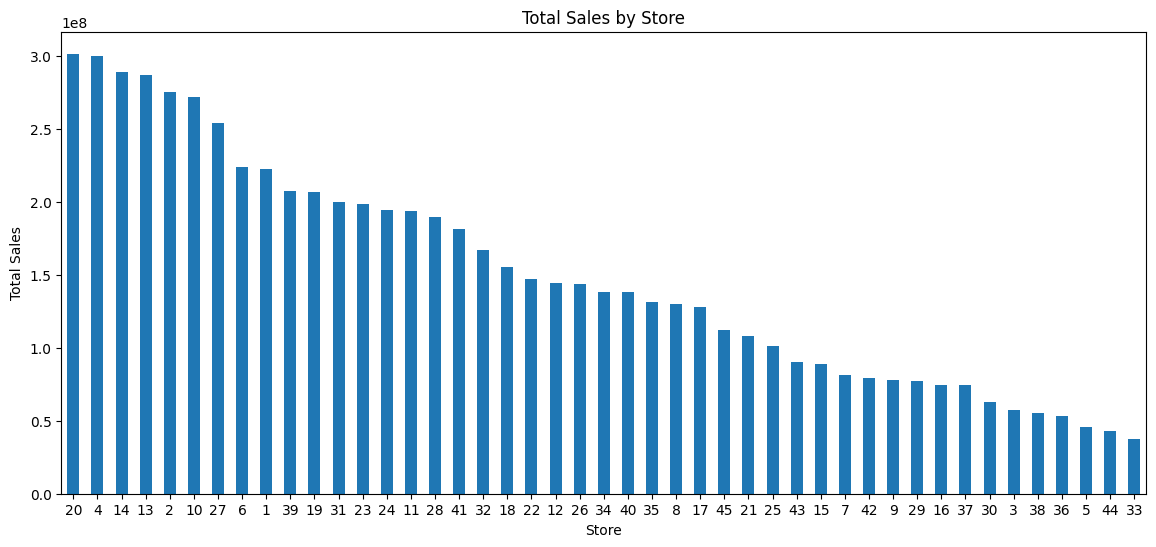

In [ ]:
plt.figure(figsize=(14, 6))

store_sales.plot(kind='bar')

plt.xlabel('Store')
plt.ylabel('Total Sales')
plt.title('Total Sales by Store')

plt.xticks(rotation=0)

plt.show()

In [ ]:
avg_store_sales = (
    df.groupby('Store')['Weekly_Sales']
      .mean()
      .sort_values(ascending=False)
)

print(avg_store_sales)

Store
20    29508.301592
4     29161.210415
14    28784.851727
13    27355.136891
2     26898.070031
10    26332.303819
27    24826.984536
6     21913.243624
1     21710.543621
39    21000.763562
19    20362.126734
23    19776.180881
31    19681.907464
11    19276.762751
24    18969.106500
28    18714.889803
41    17976.004648
32    16351.621855
18    15733.313136
22    15181.218886
12    14867.308619
26    14554.129672
35    13803.596986
40    13763.632803
34    13522.081671
43    13415.114118
8     13133.014768
17    12954.393636
45    11662.897315
42    11443.370118
21    11283.435496
25    10308.157810
37    10297.355026
15     9002.493073
9      8772.890379
30     8764.237719
36     8584.412563
7      8358.766148
29     8158.810609
16     7863.224124
38     7492.478460
3      6373.033983
44     6038.929814
33     5728.414053
5      5053.415813
Name: Weekly_Sales, dtype: float64


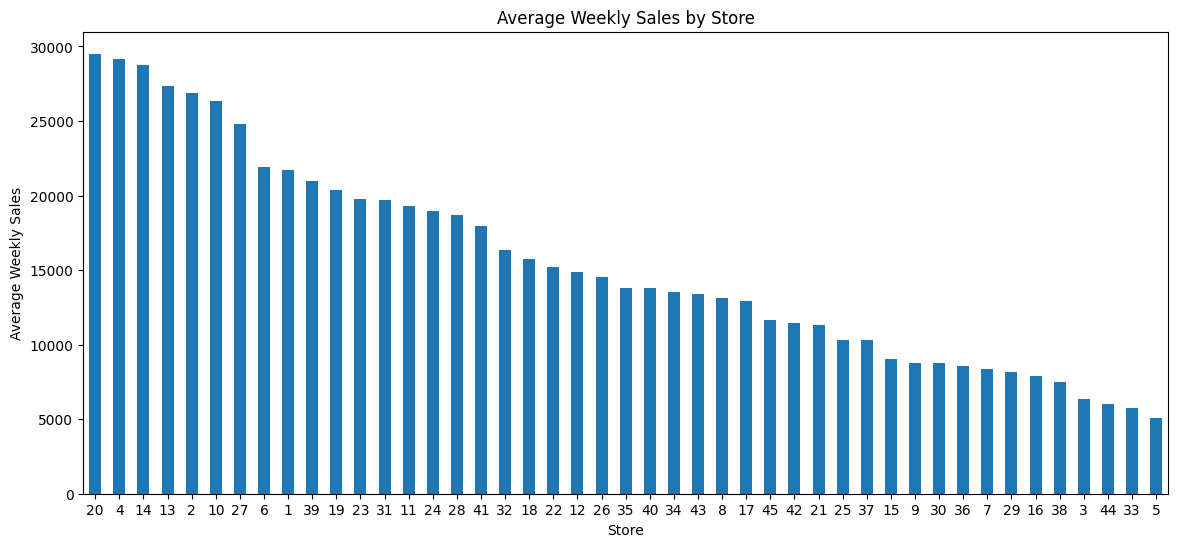

In [ ]:
plt.figure(figsize=(14, 6))

avg_store_sales.plot(kind='bar')

plt.xlabel('Store')
plt.ylabel('Average Weekly Sales')
plt.title('Average Weekly Sales by Store')

plt.xticks(rotation=0)

plt.show()

In [ ]:
dept_sales = (
    df.groupby('Dept')['Weekly_Sales']
      .sum()
      .sort_values(ascending=False)
)

print(dept_sales.head(15))

Dept
92    4.839433e+08
95    4.493202e+08
38    3.931181e+08
72    3.057252e+08
90    2.910685e+08
40    2.889360e+08
2     2.806112e+08
91    2.167817e+08
13    1.973216e+08
8     1.942808e+08
94    1.899125e+08
4     1.671467e+08
93    1.596987e+08
7     1.554776e+08
79    1.413965e+08
Name: Weekly_Sales, dtype: float64


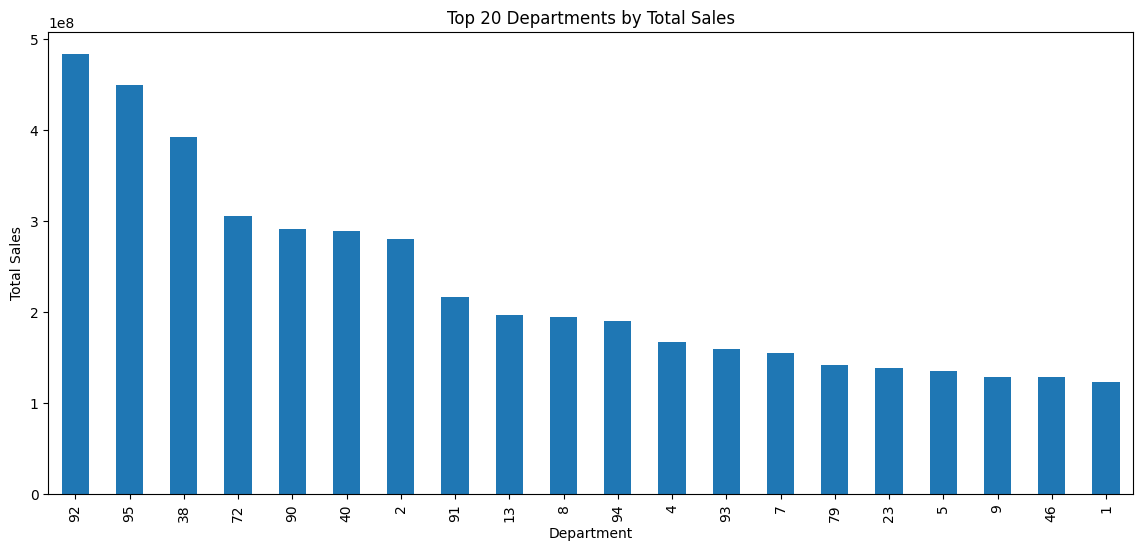

In [ ]:
plt.figure(figsize=(14, 6))

dept_sales.head(20).plot(kind='bar')

plt.xlabel('Department')
plt.ylabel('Total Sales')
plt.title('Top 20 Departments by Total Sales')

plt.show()

In [ ]:
daily_sales = (
    df.groupby('Date')['Weekly_Sales']
      .sum()
      .reset_index()
)

daily_sales.head()

,Date,Weekly_Sales
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30


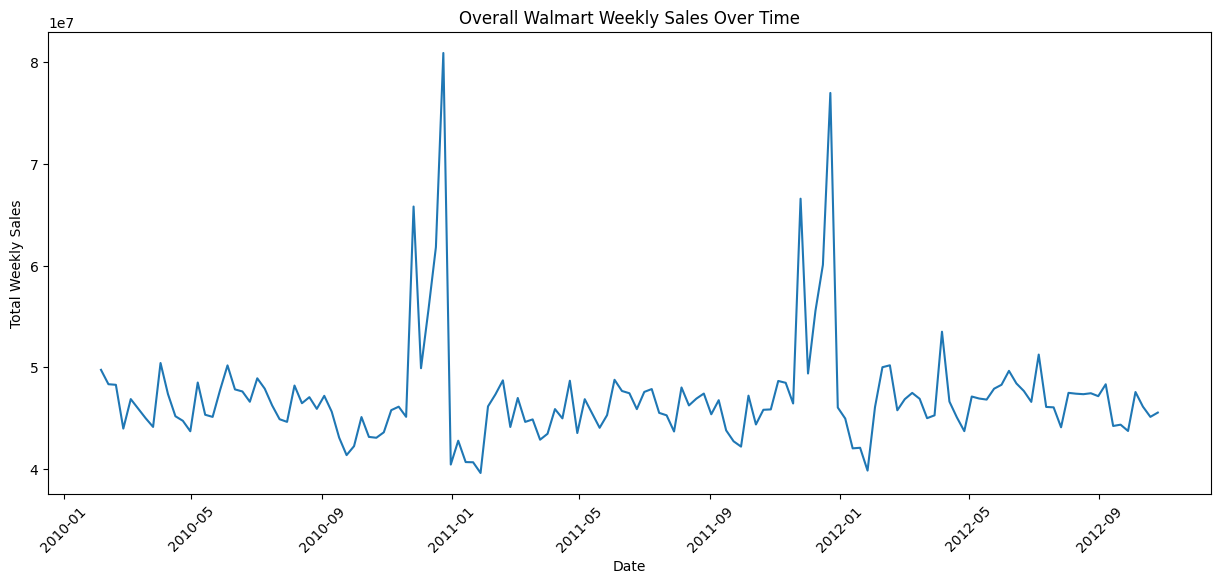

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales['Date'],
    daily_sales['Weekly_Sales']
)

plt.xlabel('Date')
plt.ylabel('Total Weekly Sales')
plt.title('Overall Walmart Weekly Sales Over Time')

plt.xticks(rotation=45)

plt.show()

In [ ]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

In [ ]:
monthly_sales = (
    df.groupby('Month')['Weekly_Sales']
      .mean()
)

print(monthly_sales)

Month
1     14126.075111
2     16008.779217
3     15416.657597
4     15650.338357
5     15776.337202
6     16326.137002
7     15861.419650
8     16062.516933
9     15095.886154
10    15243.855576
11    17491.031424
12    19355.702141
Name: Weekly_Sales, dtype: float64


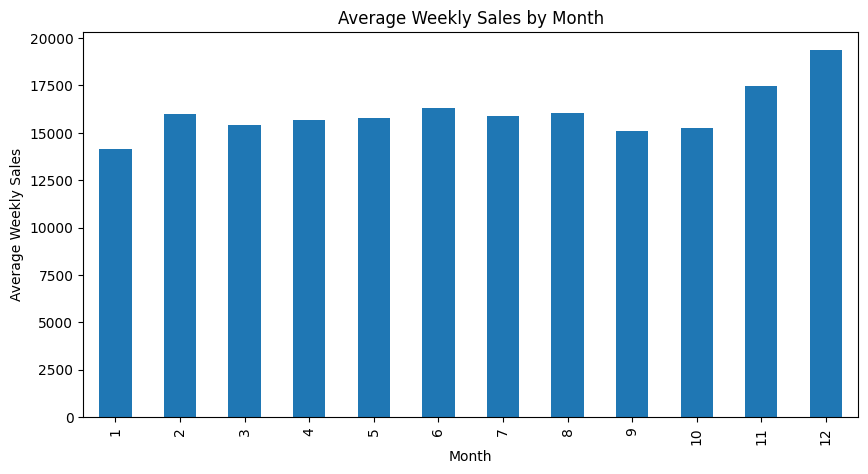

In [ ]:
plt.figure(figsize=(10, 5))

monthly_sales.plot(kind='bar')

plt.xlabel('Month')
plt.ylabel('Average Weekly Sales')
plt.title('Average Weekly Sales by Month')

plt.show()

In [ ]:
yearly_sales = (
    df.groupby('Year')['Weekly_Sales']
      .mean()
)

print(yearly_sales)

Year
2010    16270.275737
2011    15954.070675
2012    15694.948597
Name: Weekly_Sales, dtype: float64


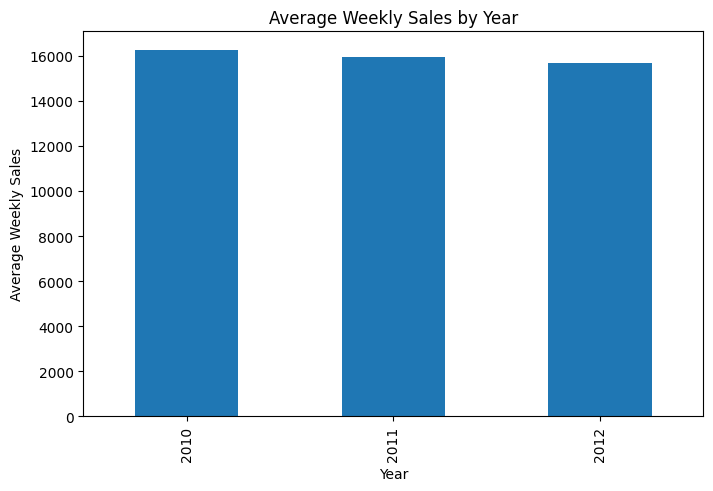

In [ ]:
plt.figure(figsize=(8, 5))

yearly_sales.plot(kind='bar')

plt.xlabel('Year')
plt.ylabel('Average Weekly Sales')
plt.title('Average Weekly Sales by Year')

plt.show()

In [ ]:
holiday_sales = (
    df.groupby('IsHoliday')['Weekly_Sales']
      .mean()
)

print(holiday_sales)

IsHoliday
False    15901.445069
True     17035.823187
Name: Weekly_Sales, dtype: float64


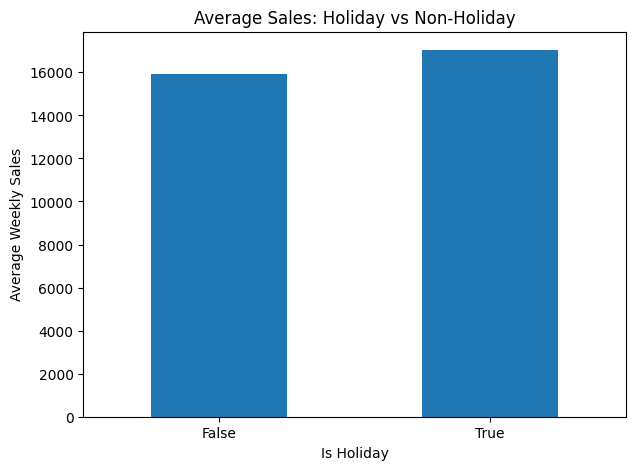

In [ ]:
plt.figure(figsize=(7, 5))

holiday_sales.plot(kind='bar')

plt.xlabel('Is Holiday')
plt.ylabel('Average Weekly Sales')
plt.title('Average Sales: Holiday vs Non-Holiday')

plt.xticks(rotation=0)

plt.show()

In [ ]:
type_sales = (
    df.groupby('Type')['Weekly_Sales']
      .mean()
)

print(type_sales)

Type
A    20099.568043
B    12237.075977
C     9519.532538
Name: Weekly_Sales, dtype: float64


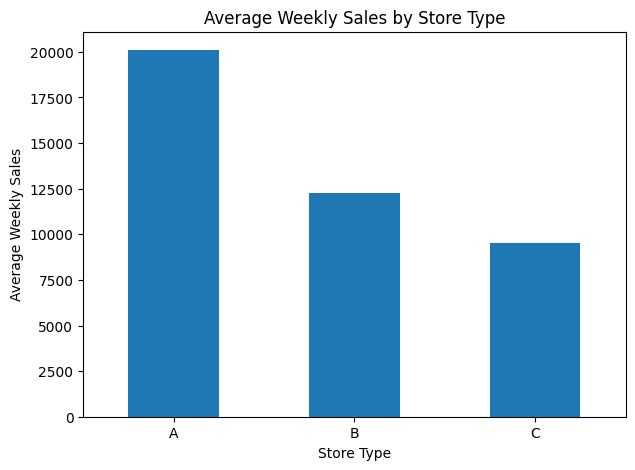

In [ ]:
plt.figure(figsize=(7, 5))

type_sales.plot(kind='bar')

plt.xlabel('Store Type')
plt.ylabel('Average Weekly Sales')
plt.title('Average Weekly Sales by Store Type')

plt.xticks(rotation=0)

plt.show()

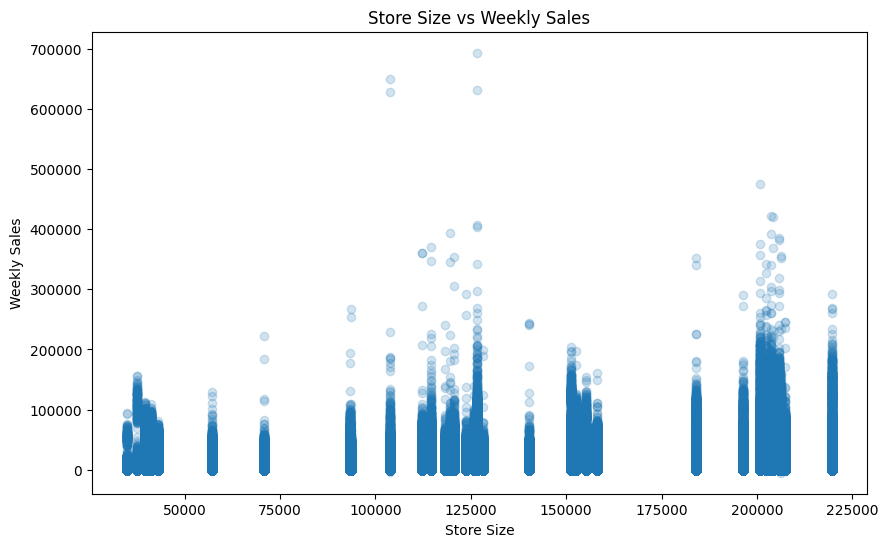

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['Size'],
    df['Weekly_Sales'],
    alpha=0.2
)

plt.xlabel('Store Size')
plt.ylabel('Weekly Sales')
plt.title('Store Size vs Weekly Sales')

plt.show()

In [ ]:
numeric_cols = [
    'Weekly_Sales',
    'Temperature',
    'Fuel_Price',
    'CPI',
    'Unemployment',
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5'
]

correlation = df[numeric_cols].corr()

print(correlation['Weekly_Sales'].sort_values(ascending=False))

Weekly_Sales    1.000000
MarkDown5       0.090362
MarkDown1       0.085251
MarkDown3       0.060385
MarkDown4       0.045414
MarkDown2       0.024130
Fuel_Price     -0.000120
Temperature    -0.002312
CPI            -0.020921
Unemployment   -0.025864
Name: Weekly_Sales, dtype: float64


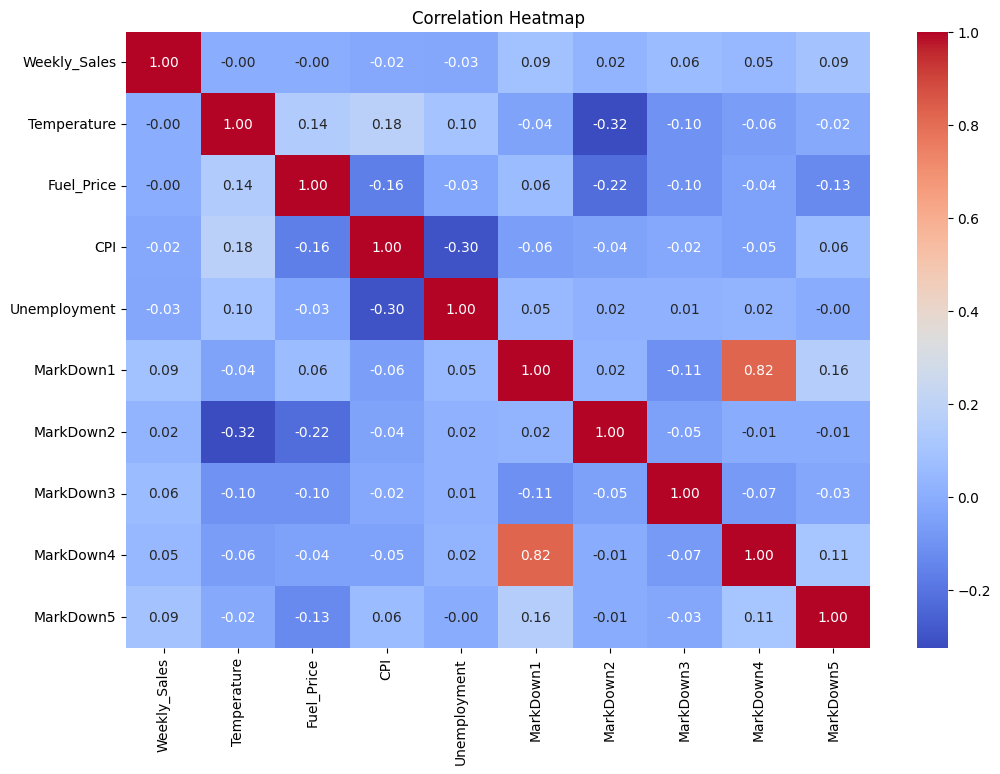

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [ ]:
markdown_cols = [
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5'
]

markdown_missing = df[markdown_cols].isnull().mean() * 100

print(markdown_missing)

MarkDown1    64.257181
MarkDown2    73.611025
MarkDown3    67.480845
MarkDown4    67.984676
MarkDown5    64.079038
dtype: float64


In [ ]:
duplicates = df.duplicated(
    subset=['Store', 'Dept', 'Date']
).sum()

print("Duplicate Store-Dept-Date records:", duplicates)

Duplicate Store-Dept-Date records: 0


In [ ]:
store_dept_sales = (
    df.groupby(['Store', 'Dept'])['Weekly_Sales']
      .agg(['count', 'mean', 'sum'])
      .sort_values('sum', ascending=False)
)

store_dept_sales.head(10)

,,count,mean,sum
Store,Dept,,,
14,92,143,182527.956014,26101497.71
2,92,143,164840.230979,23572153.03
20,92,143,164633.741538,23542625.04
13,92,143,162034.099301,23170876.20
4,92,143,159365.107902,22789210.43
20,95,143,150613.955385,21537795.62
4,95,143,147236.473706,21054815.74
27,92,143,146518.141399,20952094.22
14,95,143,144446.932517,20655911.35


In [ ]:
df.to_csv('/content/walmart_eda_ready.csv', index=False)

print("EDA-ready dataset saved successfully.")

EDA-ready dataset saved successfully.


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDate range:")
print(df['Date'].min(), "to", df['Date'].max())

Dataset shape: (421570, 18)

Columns:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday', 'Type', 'Size', 'Year', 'Month']

Missing values:
MarkDown2       310322
MarkDown4       286603
MarkDown3       284479
MarkDown1       270889
MarkDown5       270138
Store                0
Dept                 0
Fuel_Price           0
Weekly_Sales         0
Temperature          0
dtype: int64

Date range:
2010-02-05 00:00:00 to 2012-10-26 00:00:00


In [ ]:
import pandas as pd
import numpy as np

# Ensure Date is in datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Sort data chronologically for each store and department
df = df.sort_values(
    ['Store', 'Dept', 'Date']
).reset_index(drop=True)

# Handle missing Markdown values
markdown_cols = [
    'MarkDown1', 'MarkDown2', 'MarkDown3',
    'MarkDown4', 'MarkDown5'
]

for col in markdown_cols:
    # Record whether the original value was missing
    df[col + '_Missing'] = df[col].isna().astype(int)

    # Use zero as a practical imputation assumption
    df[col] = df[col].fillna(0)

# Handle missing values in other numerical external factors
external_cols = [
    'Temperature', 'Fuel_Price', 'CPI', 'Unemployment'
]

for col in external_cols:
    df[col] = df.groupby('Store')[col].transform(
        lambda s: s.fillna(s.median())
    )
    df[col] = df[col].fillna(df[col].median())

print("Dataset shape:", df.shape)
print("Total missing values:", df.isna().sum().sum())
print("Duplicate Store-Dept-Date rows:",
      df.duplicated(['Store', 'Dept', 'Date']).sum())

display(df.head())

Dataset shape: (421570, 23)
Total missing values: 0
Duplicate Store-Dept-Date rows: 0


,Store,Dept,Date,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,...,IsHoliday,Type,Size,Year,Month,MarkDown1_Missing,MarkDown2_Missing,MarkDown3_Missing,MarkDown4_Missing,MarkDown5_Missing
0,1,1,2010-02-05,24924.50,42.31,2.572,0.0,0.0,0.0,0.0,...,False,A,151315,2010,2,1,1,1,1,1
1,1,1,2010-02-12,46039.49,38.51,2.548,0.0,0.0,0.0,0.0,...,True,A,151315,2010,2,1,1,1,1,1
2,1,1,2010-02-19,41595.55,39.93,2.514,0.0,0.0,0.0,0.0,...,False,A,151315,2010,2,1,1,1,1,1
3,1,1,2010-02-26,19403.54,46.63,2.561,0.0,0.0,0.0,0.0,...,False,A,151315,2010,2,1,1,1,1,1
4,1,1,2010-03-05,21827.90,46.50,2.625,0.0,0.0,0.0,0.0,...,False,A,151315,2010,3,1,1,1,1,1


In [ ]:
# Calendar features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['Quarter'] = df['Date'].dt.quarter

# Previous sales for each Store-Department combination
grouped_sales = df.groupby(['Store', 'Dept'])['Weekly_Sales']

df['Lag_1'] = grouped_sales.shift(1)
df['Lag_2'] = grouped_sales.shift(2)
df['Lag_4'] = grouped_sales.shift(4)

# Rolling statistics using previous weeks only
df['Rolling_Mean_4'] = (
    df.groupby(['Store', 'Dept'])['Weekly_Sales']
      .transform(lambda s: s.shift(1).rolling(4, min_periods=2).mean())
)

df['Rolling_Std_4'] = (
    df.groupby(['Store', 'Dept'])['Weekly_Sales']
      .transform(lambda s: s.shift(1).rolling(4, min_periods=2).std())
)

# Remove rows without sufficient previous sales history
df_model = df.dropna(
    subset=['Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4']
).copy()

print("Original dataset rows:", len(df))
print("Rows available for modeling:", len(df_model))
print("New temporal features created:")
print([
    'Year', 'Month', 'WeekOfYear', 'Quarter',
    'Lag_1', 'Lag_2', 'Lag_4',
    'Rolling_Mean_4', 'Rolling_Std_4'
])

display(
    df_model[
        ['Store', 'Dept', 'Date', 'Weekly_Sales',
         'Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4']
    ].head(10)
)

Original dataset rows: 421570
Rows available for modeling: 408436
New temporal features created:
['Year', 'Month', 'WeekOfYear', 'Quarter', 'Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4', 'Rolling_Std_4']


,Store,Dept,Date,Weekly_Sales,Lag_1,Lag_2,Lag_4,Rolling_Mean_4
4,1,1,2010-03-05,21827.90,19403.54,41595.55,24924.50,32990.7700
5,1,1,2010-03-12,21043.39,21827.90,19403.54,46039.49,32216.6200
6,1,1,2010-03-19,22136.64,21043.39,21827.90,41595.55,25967.5950
7,1,1,2010-03-26,26229.21,22136.64,21043.39,19403.54,21102.8675
8,1,1,2010-04-02,57258.43,26229.21,22136.64,21827.90,22809.2850
9,1,1,2010-04-09,42960.91,57258.43,26229.21,21043.39,31666.9175
10,1,1,2010-04-16,17596.96,42960.91,57258.43,22136.64,37146.2975
11,1,1,2010-04-23,16145.35,17596.96,42960.91,26229.21,36011.3775
12,1,1,2010-04-30,16555.11,16145.35,17596.96,57258.43,33490.4125
13,1,1,2010-05-07,17413.94,16555.11,16145.35,42960.91,23314.5825


In [ ]:
# Sort unique dates to create a chronological 80:20 split
unique_dates = sorted(df_model['Date'].unique())

split_index = int(len(unique_dates) * 0.80)
cutoff_date = unique_dates[split_index]

train_df = df_model[df_model['Date'] < cutoff_date].copy()
test_df = df_model[df_model['Date'] >= cutoff_date].copy()

print("Cutoff date:", pd.Timestamp(cutoff_date))
print("\nTraining period:")
print(train_df['Date'].min(), "to", train_df['Date'].max())

print("\nTesting period:")
print(test_df['Date'].min(), "to", test_df['Date'].max())

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

Cutoff date: 2012-04-20 00:00:00

Training period:
2010-03-05 00:00:00 to 2012-04-13 00:00:00

Testing period:
2012-04-20 00:00:00 to 2012-10-26 00:00:00

Training rows: 325663
Testing rows: 82773


In [ ]:
basic_features = [
    'Store', 'Dept', 'IsHoliday', 'Type', 'Size'
]

temporal_features = basic_features + [
    'Year', 'Month', 'WeekOfYear', 'Quarter',
    'Lag_1', 'Lag_2', 'Lag_4',
    'Rolling_Mean_4', 'Rolling_Std_4'
]

external_features = temporal_features + [
    'Temperature', 'Fuel_Price', 'CPI', 'Unemployment',
    'MarkDown1', 'MarkDown2', 'MarkDown3',
    'MarkDown4', 'MarkDown5',
    'MarkDown1_Missing', 'MarkDown2_Missing',
    'MarkDown3_Missing', 'MarkDown4_Missing',
    'MarkDown5_Missing'
]

experiments = {
    'A_Basic': basic_features,
    'B_Temporal': temporal_features,
    'C_Temporal_External': external_features
}

for name, columns in experiments.items():
    print(name, "-", len(columns), "features")

A_Basic - 5 features
B_Temporal - 14 features
C_Temporal_External - 28 features


In [ ]:
%pip -q install xgboost lightgbm

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=60, max_depth=18,
        min_samples_leaf=3, random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBRegressor(
        n_estimators=150, max_depth=8, learning_rate=0.08,
        subsample=0.8, colsample_bytree=0.8,
        objective='reg:squarederror', random_state=42, n_jobs=-1
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=150, learning_rate=0.08,
        num_leaves=31, random_state=42, n_jobs=-1, verbosity=-1
    )
}

results = []
trained_models = {}
predictions = {}

y_train = train_df['Weekly_Sales']
y_test = test_df['Weekly_Sales']

for experiment_name, selected_features in experiments.items():
    print(f"\nRunning experiment: {experiment_name}")

    X_train = pd.get_dummies(
        train_df[selected_features],
        columns=[c for c in ['Store', 'Dept', 'Type'] if c in selected_features],
        dtype=int
    )

    X_test = pd.get_dummies(
        test_df[selected_features],
        columns=[c for c in ['Store', 'Dept', 'Type'] if c in selected_features],
        dtype=int
    )

    # Make training and testing columns identical
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    # Replace invalid values and fill missing values
    X_train = X_train.replace([np.inf, -np.inf], np.nan)
    X_test = X_test.replace([np.inf, -np.inf], np.nan)

    medians = X_train.median()
    X_train = X_train.fillna(medians).fillna(0)
    X_test = X_test.fillna(medians).fillna(0)

    for model_name, base_model in models.items():
        model = base_model
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))
        r2 = r2_score(y_test, pred)

        positive = y_test > 0
        mape = (
            np.abs((y_test[positive] - pred[positive]) / y_test[positive]).mean()
            * 100
        )

        wape = (
            np.abs(y_test.to_numpy() - pred).sum()
            / np.abs(y_test.to_numpy()).sum()
            * 100
        )

        results.append({
            'Experiment': experiment_name,
            'Model': model_name,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE_positive_sales_%': mape,
            'WAPE_%': wape,
            'R2': r2
        })

        key = (experiment_name, model_name)
        trained_models[key] = {
            'model': model,
            'columns': X_train.columns.tolist()
        }
        predictions[key] = pred

    print("Completed:", experiment_name)

results_df = pd.DataFrame(results).sort_values('RMSE')
display(results_df.round(3))

PATH = '/content/drive/MyDrive/Walmart_Demand_Forecasting/'
results_df.to_csv(PATH + 'model_comparison_results.csv', index=False)

print("Results saved to Google Drive.")



Running experiment: A_Basic
Completed: A_Basic

Running experiment: B_Temporal
Completed: B_Temporal

Running experiment: C_Temporal_External
Completed: C_Temporal_External


,Experiment,Model,MAE,RMSE,MAPE_positive_sales_%,WAPE_%,R2
6,B_Temporal,XGBoost,1310.837,2747.137,695.067,8.298,0.984
10,C_Temporal_External,XGBoost,1397.311,2850.416,1599.464,8.845,0.983
5,B_Temporal,Random Forest,1340.368,2864.598,1184.675,8.485,0.983
9,C_Temporal_External,Random Forest,1362.464,2880.289,1049.334,8.625,0.983
7,B_Temporal,LightGBM,1372.404,2893.577,1023.986,8.688,0.983
11,C_Temporal_External,LightGBM,1441.258,2992.306,2014.672,9.124,0.981
4,B_Temporal,Linear Regression,1723.709,3281.262,4135.160,10.912,0.978
8,C_Temporal_External,Linear Regression,1823.491,3332.484,4524.974,11.543,0.977
3,A_Basic,LightGBM,4175.584,6716.439,22430.986,26.433,0.907
2,A_Basic,XGBoost,4434.229,6787.101,42172.933,28.070,0.905


Results saved to Google Drive.


In [ ]:
# Display the best-performing model by RMSE
best_row = results_df.sort_values('RMSE').iloc[0]

print("Best Experiment:", best_row['Experiment'])
print("Best Model:", best_row['Model'])
print("MAE:", round(best_row['MAE'], 2))
print("RMSE:", round(best_row['RMSE'], 2))
print("WAPE:", round(best_row['WAPE_%'], 2), "%")
print("R²:", round(best_row['R2'], 4))

Best Experiment: B_Temporal
Best Model: XGBoost
MAE: 1310.84
RMSE: 2747.14
WAPE: 8.3 %
R²: 0.9844


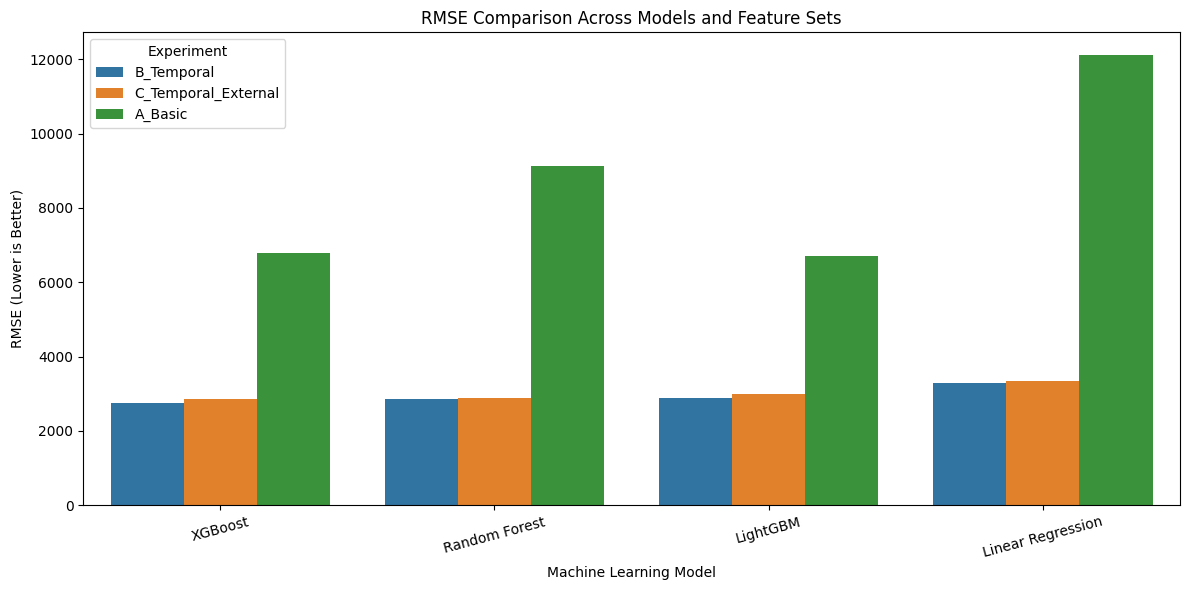

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE',
    hue='Experiment'
)

plt.title('RMSE Comparison Across Models and Feature Sets')
plt.xlabel('Machine Learning Model')
plt.ylabel('RMSE (Lower is Better)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
display(
    results_df.sort_values(
        ['Experiment', 'RMSE']
    ).round(3)
)

,Experiment,Model,MAE,RMSE,MAPE_positive_sales_%,WAPE_%,R2
3,A_Basic,LightGBM,4175.584,6716.439,22430.986,26.433,0.907
2,A_Basic,XGBoost,4434.229,6787.101,42172.933,28.070,0.905
1,A_Basic,Random Forest,6239.780,9126.038,53388.715,39.500,0.827
0,A_Basic,Linear Regression,7957.585,12118.110,37561.652,50.374,0.696
6,B_Temporal,XGBoost,1310.837,2747.137,695.067,8.298,0.984
5,B_Temporal,Random Forest,1340.368,2864.598,1184.675,8.485,0.983
7,B_Temporal,LightGBM,1372.404,2893.577,1023.986,8.688,0.983
4,B_Temporal,Linear Regression,1723.709,3281.262,4135.160,10.912,0.978
10,C_Temporal_External,XGBoost,1397.311,2850.416,1599.464,8.845,0.983
9,C_Temporal_External,Random Forest,1362.464,2880.289,1049.334,8.625,0.983


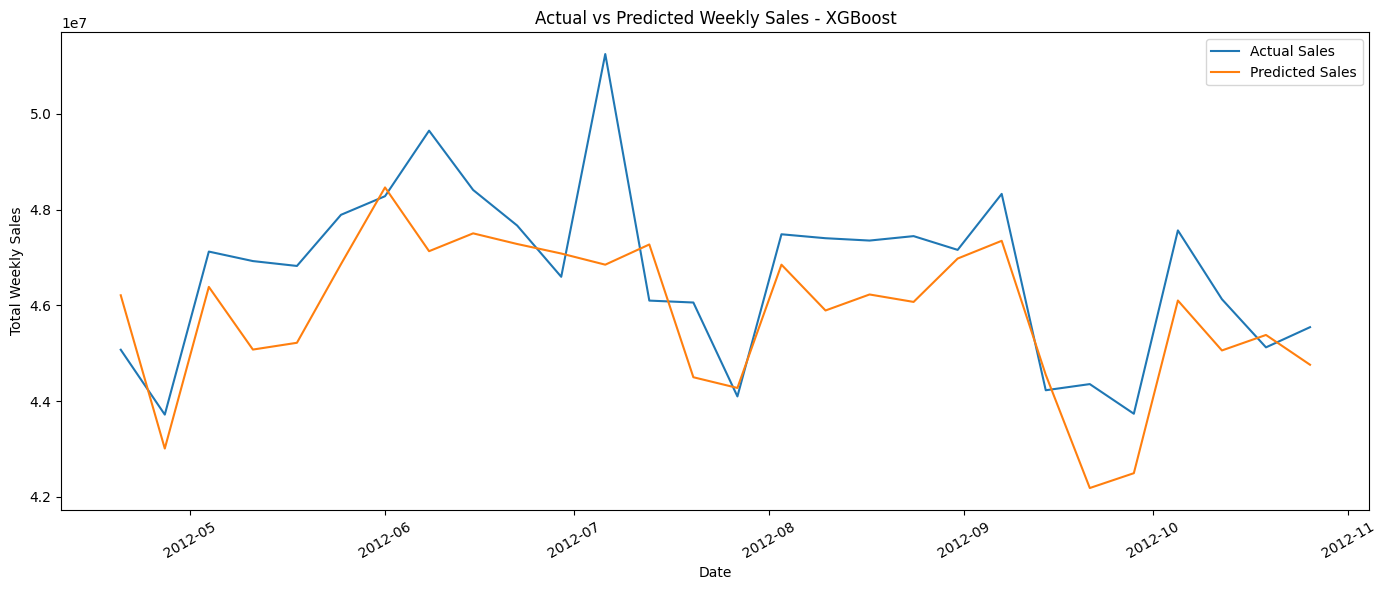

In [ ]:
best_key = (best_row['Experiment'], best_row['Model'])

best_pred = predictions[best_key]

plot_df = pd.DataFrame({
    'Date': test_df['Date'].to_numpy(),
    'Actual': test_df['Weekly_Sales'].to_numpy(),
    'Predicted': best_pred
})

# Aggregate sales across stores and departments by week
weekly_comparison = (
    plot_df.groupby('Date')[['Actual', 'Predicted']]
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    weekly_comparison.index,
    weekly_comparison['Actual'],
    label='Actual Sales'
)

plt.plot(
    weekly_comparison.index,
    weekly_comparison['Predicted'],
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Weekly Sales - XGBoost')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:

for name, obj in globals().copy().items():
    if hasattr(obj, "feature_importances_"):
        print(name, "->", type(obj).__name__)


RandomForestRegressor -> ABCMeta
XGBRegressor -> type
LGBMRegressor -> type
base_model -> LGBMRegressor
model -> LGBMRegressor


In [ ]:

# Find trained model objects in the current Colab session

for name, obj in globals().copy().items():
    if name.startswith("_"):
        continue

    if type(obj).__module__.startswith(("xgboost", "lightgbm", "sklearn")):
        if hasattr(obj, "predict"):
            fitted = hasattr(obj, "n_features_in_") or hasattr(obj, "get_booster")
            print(f"Variable: {name}")
            print(f"Model: {type(obj).__name__}")
            print(f"Looks fitted: {fitted}")
            print("-" * 30)


Variable: base_model
Model: LGBMRegressor
Looks fitted: True
------------------------------
Variable: model
Model: LGBMRegressor
Looks fitted: True
------------------------------


In [ ]:

# Check common XGBoost model variable names

for name in ["xgb_model", "xgboost_model", "best_xgb",
             "best_xgb_model", "xgb", "best_model"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj).__name__)


In [ ]:
display(
    results_df[
        ['Experiment', 'Model', 'MAE', 'RMSE',
         'MAPE_positive_sales_%', 'WAPE_%', 'R2']
    ].round(3)
)

,Experiment,Model,MAE,RMSE,MAPE_positive_sales_%,WAPE_%,R2
6,B_Temporal,XGBoost,1310.837,2747.137,695.067,8.298,0.984
10,C_Temporal_External,XGBoost,1397.311,2850.416,1599.464,8.845,0.983
5,B_Temporal,Random Forest,1340.368,2864.598,1184.675,8.485,0.983
9,C_Temporal_External,Random Forest,1362.464,2880.289,1049.334,8.625,0.983
7,B_Temporal,LightGBM,1372.404,2893.577,1023.986,8.688,0.983
11,C_Temporal_External,LightGBM,1441.258,2992.306,2014.672,9.124,0.981
4,B_Temporal,Linear Regression,1723.709,3281.262,4135.160,10.912,0.978
8,C_Temporal_External,Linear Regression,1823.491,3332.484,4524.974,11.543,0.977
3,A_Basic,LightGBM,4175.584,6716.439,22430.986,26.433,0.907
2,A_Basic,XGBoost,4434.229,6787.101,42172.933,28.070,0.905


In [ ]:
#Inspect existing project variables

print("results_df available:", "results_df" in globals())
print("df available:", "df" in globals())
print("X_test available:", "X_test" in globals())
print("y_test available:", "y_test" in globals())

print("\nPossible prediction and model variables:")

for name, obj in list(globals().items()):
    name_lower = name.lower()

    if any(word in name_lower for word in [
        "pred", "actual", "xgb", "model", "test"
    ]):
        if not callable(obj) and not name.startswith("_"):
            print(name, "| type:", type(obj).__name__)


results_df available: True
df available: True
X_test available: True
y_test available: True

Possible prediction and model variables:
df_model | type: DataFrame
test_df | type: DataFrame
models | type: dict
trained_models | type: dict
predictions | type: dict
y_test | type: Series
X_test | type: DataFrame
model_name | type: str
base_model | type: LGBMRegressor
model | type: LGBMRegressor
pred | type: ndarray
best_pred | type: ndarray


In [ ]:
display(results_df.round(3))

,Experiment,Model,MAE,RMSE,MAPE_positive_sales_%,WAPE_%,R2
6,B_Temporal,XGBoost,1310.837,2747.137,695.067,8.298,0.984
10,C_Temporal_External,XGBoost,1397.311,2850.416,1599.464,8.845,0.983
5,B_Temporal,Random Forest,1340.368,2864.598,1184.675,8.485,0.983
9,C_Temporal_External,Random Forest,1362.464,2880.289,1049.334,8.625,0.983
7,B_Temporal,LightGBM,1372.404,2893.577,1023.986,8.688,0.983
11,C_Temporal_External,LightGBM,1441.258,2992.306,2014.672,9.124,0.981
4,B_Temporal,Linear Regression,1723.709,3281.262,4135.160,10.912,0.978
8,C_Temporal_External,Linear Regression,1823.491,3332.484,4524.974,11.543,0.977
3,A_Basic,LightGBM,4175.584,6716.439,22430.986,26.433,0.907
2,A_Basic,XGBoost,4434.229,6787.101,42172.933,28.070,0.905


In [ ]:

# Create a table of actual and predicted sales

error_df = test_df[['Store', 'Dept', 'Date']].copy()

error_df['Actual_Sales'] = y_test.to_numpy()
error_df['Predicted_Sales'] = best_pred

error_df['Error'] = (
    error_df['Actual_Sales'] - error_df['Predicted_Sales']
)

error_df['Absolute_Error'] = error_df['Error'].abs()

print("Error dataset shape:", error_df.shape)
display(error_df.head())


Error dataset shape: (82773, 7)


,Store,Dept,Date,Actual_Sales,Predicted_Sales,Error,Absolute_Error
115,1,1,2012-04-20,16976.19,23705.492188,-6729.302188,6729.302188
116,1,1,2012-04-27,16347.60,19063.111328,-2715.511328,2715.511328
117,1,1,2012-05-04,17147.44,18941.843750,-1794.403750,1794.403750
118,1,1,2012-05-11,18164.20,19606.474609,-1442.274609,1442.274609
119,1,1,2012-05-18,18517.79,18303.613281,214.176719,214.176719


In [ ]:

# Calculate forecasting errors for each store and department

group_errors = (
    error_df.groupby(['Store', 'Dept'])
    .agg(
        Actual_Sales=('Actual_Sales', 'sum'),
        MAE=('Absolute_Error', 'mean'),
        Total_Error=('Error', 'sum'),
        Records=('Error', 'count')
    )
    .reset_index()
)

# Show combinations with the highest average error
group_errors = group_errors.sort_values(
    'MAE', ascending=False
)

display(group_errors.head(10))


,Store,Dept,Actual_Sales,MAE,Total_Error,Records
1003,14,92,4474714.95,21535.157433,-447663.690625,28
1444,20,92,4756712.82,12605.799129,-38007.351875,28
272,4,72,2579135.71,11154.327679,68421.678750,28
697,10,72,3020114.58,10074.514900,37430.384688,28
1006,14,95,3490128.30,9493.882455,-134957.325000,28
2646,38,38,2053697.04,9291.007455,-7979.428750,28
2022,28,92,2718121.15,9260.498292,52270.235937,28
286,4,95,4594988.21,9015.653862,251186.538125,28
930,13,92,4859610.73,8656.717098,240218.636250,28
1731,24,92,3545512.23,8647.660882,52599.019062,28


In [ ]:

print(group_errors.columns.tolist())
print("Rows:", len(group_errors))

display(
    group_errors[
        ['Store', 'Dept', 'Actual_Sales', 'MAE',
         'Total_Error', 'Records']
    ].head(10).to_string(index=False)
)


['Store', 'Dept', 'Actual_Sales', 'MAE', 'Total_Error', 'Records']
Rows: 3138


' Store  Dept  Actual_Sales          MAE    Total_Error  Records\n    14    92    4474714.95 21535.157433 -447663.690625       28\n    20    92    4756712.82 12605.799129  -38007.351875       28\n     4    72    2579135.71 11154.327679   68421.678750       28\n    10    72    3020114.58 10074.514900   37430.384688       28\n    14    95    3490128.30  9493.882455 -134957.325000       28\n    38    38    2053697.04  9291.007455   -7979.428750       28\n    28    92    2718121.15  9260.498292   52270.235937       28\n     4    95    4594988.21  9015.653862  251186.538125       28\n    13    92    4859610.73  8656.717098  240218.636250       28\n    24    92    3545512.23  8647.660882   52599.019062       28'

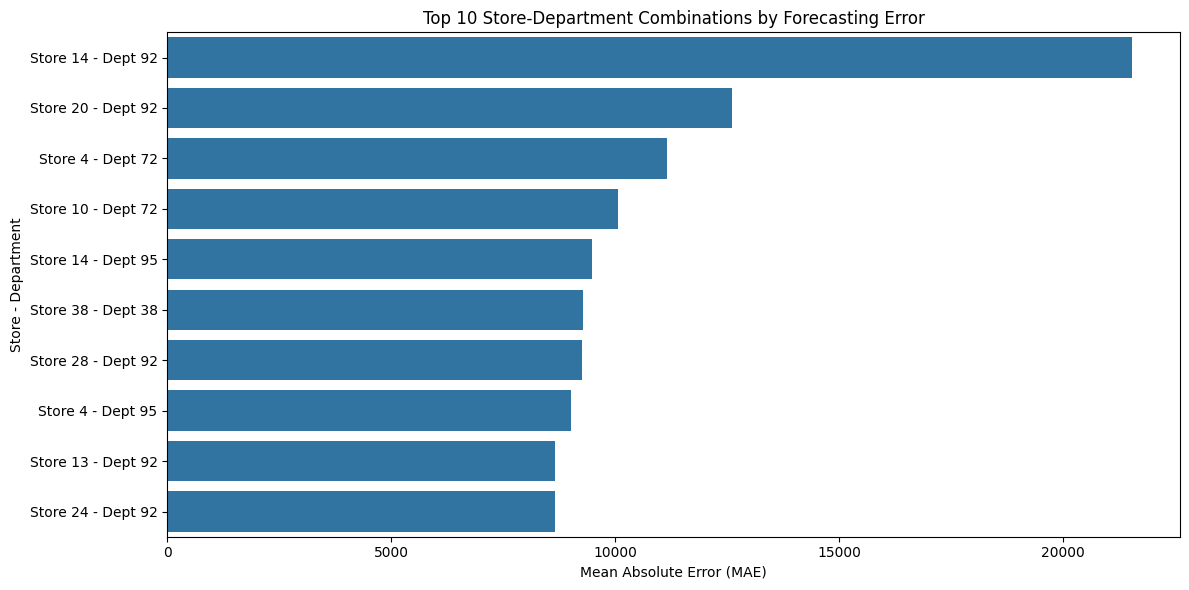

In [ ]:

top_errors = group_errors.head(10).copy()

top_errors['Store_Dept'] = (
    'Store ' + top_errors['Store'].astype(str)
    + ' - Dept ' + top_errors['Dept'].astype(str)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_errors,
    x='MAE',
    y='Store_Dept'
)

plt.title('Top 10 Store-Department Combinations by Forecasting Error')
plt.xlabel('Mean Absolute Error (MAE)')
plt.ylabel('Store - Department')
plt.tight_layout()
plt.show()


In [ ]:

# Calculate prediction errors and flag unusual sales

error_df['Error_Percent'] = (
    error_df['Error']
    / error_df['Actual_Sales'].abs().replace(0, np.nan)
) * 100

error_limit = error_df['Error'].std() * 2

error_df['Anomaly'] = (
    error_df['Error'].abs() > error_limit
)

print("Error threshold:", round(error_limit, 2))
print("Potential anomalies:", error_df['Anomaly'].sum())

display(
    error_df[error_df['Anomaly']]
    .sort_values('Absolute_Error', ascending=False)
    .head(10)
)


Error threshold: 5462.29
Potential anomalies: 3687


,Store,Dept,Date,Actual_Sales,Predicted_Sales,Error,Absolute_Error,Error_Percent,Anomaly
149306,16,9,2012-10-19,111246.19,39289.949219,71956.240781,71956.240781,64.681982,True
361498,39,3,2012-09-07,27998.09,85156.578125,-57158.488125,57158.488125,-204.151384,True
332310,35,11,2012-06-01,76321.27,22642.316406,53678.953594,53678.953594,70.332888,True
137340,14,92,2012-08-31,138589.09,190351.578125,-51762.488125,51762.488125,-37.349613,True
87940,10,3,2012-08-03,120827.95,69977.609375,50850.340625,50850.340625,42.084915,True
118027,13,3,2012-09-07,114230.60,63562.093750,50668.506250,50668.506250,44.356334,True
276186,28,92,2012-09-07,153061.49,103307.734375,49753.755625,49753.755625,32.505731,True
137330,14,92,2012-06-22,134236.16,183230.140625,-48993.980625,48993.980625,-36.498348,True
166629,17,92,2012-09-07,105950.68,58203.148438,47747.531562,47747.531562,45.065809,True
208685,22,11,2012-06-22,60650.80,13876.153320,46774.646680,46774.646680,77.121236,True


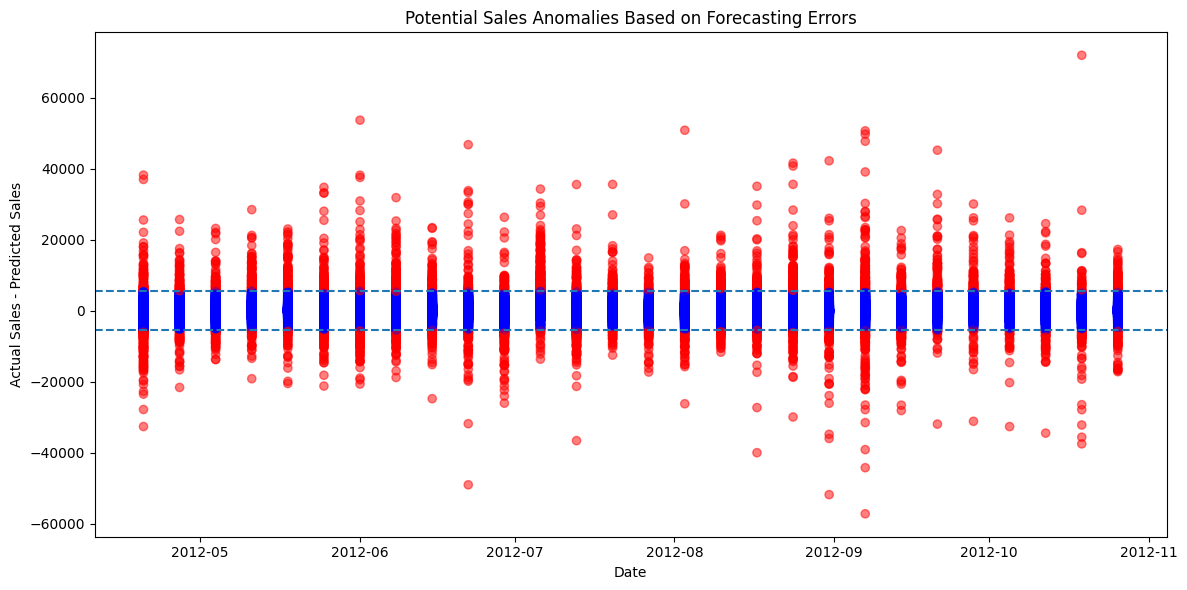

In [ ]:

plt.figure(figsize=(12, 6))

plt.scatter(
    error_df['Date'],
    error_df['Error'],
    c=error_df['Anomaly'].map({True: 'red', False: 'blue'}),
    alpha=0.5
)

plt.axhline(error_limit, linestyle='--')
plt.axhline(-error_limit, linestyle='--')

plt.title('Potential Sales Anomalies Based on Forecasting Errors')
plt.xlabel('Date')
plt.ylabel('Actual Sales - Predicted Sales')
plt.tight_layout()
plt.show()


In [ ]:

try:
    import shap
    print("SHAP version:", shap.__version__)
except ImportError:
    print("SHAP is not installed.")


SHAP version: 0.54.1


In [ ]:

import shap

# Get the best model and its feature columns
best_model = trained_models[best_key]['model']
best_columns = trained_models[best_key]['columns']

# Prepare test data with the same encoding used during training
shap_features = best_columns

X_shap = pd.get_dummies(
    test_df[experiments[best_key[0]]],
    columns=[
        c for c in ['Store', 'Dept', 'Type']
        if c in experiments[best_key[0]]
    ],
    dtype=int
)

X_shap = X_shap.reindex(columns=shap_features, fill_value=0)

# Select a sample for faster explanation
X_sample = X_shap.sample(
    n=min(500, len(X_shap)),
    random_state=42
)

print("SHAP sample shape:", X_sample.shape)
print("Best model:", type(best_model).__name__)


SHAP sample shape: (500, 139)
Best model: XGBRegressor


In [ ]:

print("Model:", type(best_model).__name__)
print("Expected model features:", best_model.n_features_in_)
print("X_sample shape:", X_sample.shape)
print("Stored feature columns:", len(best_columns))
print("Feature names match:", list(X_sample.columns) == best_columns)


Model: XGBRegressor
Expected model features: 153
X_sample shape: (500, 139)
Stored feature columns: 139
Feature names match: True


In [ ]:

# Rebuild test features using the best experiment's feature set

selected_features = experiments[best_key[0]]

X_shap = pd.get_dummies(
    test_df[selected_features].copy(),
    columns=[
        col for col in ['Store', 'Dept', 'Type']
        if col in selected_features
    ],
    dtype=int
)

X_shap = X_shap.reindex(
    columns=best_columns,
    fill_value=0
)

X_sample = X_shap.sample(
    n=min(100, len(X_shap)),
    random_state=42
)

print("Rebuilt SHAP sample:", X_sample.shape)
print("Model expects:", best_model.n_features_in_)


Rebuilt SHAP sample: (100, 139)
Model expects: 153


In [ ]:

print("Model expects:", best_model.n_features_in_)
print("Stored columns:", len(best_columns))
print("Model feature names:", best_model.get_booster().feature_names[:10])
print("Stored column names:", best_columns[:10])


Model expects: 153
Stored columns: 139
Model feature names: ['IsHoliday', 'Size', 'Year', 'Month', 'WeekOfYear', 'Quarter', 'Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4']
Stored column names: ['IsHoliday', 'Size', 'Year', 'Month', 'WeekOfYear', 'Quarter', 'Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4']


In [ ]:

model_columns = best_model.get_booster().feature_names

print("Model feature count:", len(model_columns))
print("Current feature count:", X_shap.shape[1])

missing_columns = [
    col for col in model_columns
    if col not in X_shap.columns
]

extra_columns = [
    col for col in X_shap.columns
    if col not in model_columns
]

print("Missing columns:", missing_columns)
print("Extra columns:", extra_columns)


Model feature count: 153
Current feature count: 139
Missing columns: ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'MarkDown1_Missing', 'MarkDown2_Missing', 'MarkDown3_Missing', 'MarkDown4_Missing', 'MarkDown5_Missing']
Extra columns: []


In [ ]:

model_columns = best_model.get_booster().feature_names

missing_columns = [
    col for col in model_columns
    if col not in best_columns
]

print("Model feature count:", len(model_columns))
print("Stored feature count:", len(best_columns))
print("Missing feature count:", len(missing_columns))
print("Missing features:", missing_columns)


Model feature count: 153
Stored feature count: 139
Missing feature count: 14
Missing features: ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'MarkDown1_Missing', 'MarkDown2_Missing', 'MarkDown3_Missing', 'MarkDown4_Missing', 'MarkDown5_Missing']


In [ ]:

# Use the feature names stored in the trained XGBoost model
best_columns = model_columns

X_shap = pd.get_dummies(
    test_df[experiments[best_key[0]]].copy(),
    columns=[
        col for col in ['Store', 'Dept', 'Type']
        if col in experiments[best_key[0]]
    ],
    dtype=int
)

X_shap = X_shap.reindex(
    columns=best_columns,
    fill_value=0
)

X_sample = X_shap.sample(
    n=min(100, len(X_shap)),
    random_state=42
)

print("Sample shape:", X_sample.shape)
print("Expected features:", best_model.n_features_in_)


Sample shape: (100, 153)
Expected features: 153


In [ ]:

best_key = ('B_Temporal', 'XGBoost')

best_model = trained_models[best_key]['model']
best_columns = trained_models[best_key]['columns']

print("Selected model:", best_key)
print("Expected features:", best_model.n_features_in_)
print("Stored columns:", len(best_columns))


Selected model: ('B_Temporal', 'XGBoost')
Expected features: 153
Stored columns: 139


In [ ]:

from xgboost import XGBRegressor

best_key = ('B_Temporal', 'XGBoost')
selected_features = experiments['B_Temporal']

X_train_shap = pd.get_dummies(
    train_df[selected_features].copy(),
    columns=[
        col for col in ['Store', 'Dept', 'Type']
        if col in selected_features
    ],
    dtype=int
)

X_test_shap = pd.get_dummies(
    test_df[selected_features].copy(),
    columns=[
        col for col in ['Store', 'Dept', 'Type']
        if col in selected_features
    ],
    dtype=int
)

X_test_shap = X_test_shap.reindex(
    columns=X_train_shap.columns,
    fill_value=0
)

X_train_shap = X_train_shap.replace(
    [np.inf, -np.inf], np.nan
)
X_test_shap = X_test_shap.replace(
    [np.inf, -np.inf], np.nan
)

medians = X_train_shap.median()
X_train_shap = X_train_shap.fillna(medians).fillna(0)
X_test_shap = X_test_shap.fillna(medians).fillna(0)

best_model = XGBRegressor(
    n_estimators=150,
    max_depth=8,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train_shap, y_train)
best_columns = X_train_shap.columns.tolist()

print("Model features:", best_model.n_features_in_)
print("Stored columns:", len(best_columns))


Model features: 139
Stored columns: 139


In [ ]:

X_sample = X_test_shap.sample(
    n=min(100, len(X_test_shap)),
    random_state=42
)

explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_sample)

print("SHAP values shape:", shap_values.values.shape)
print("SHAP analysis completed.")


SHAP values shape: (100, 139)
SHAP analysis completed.


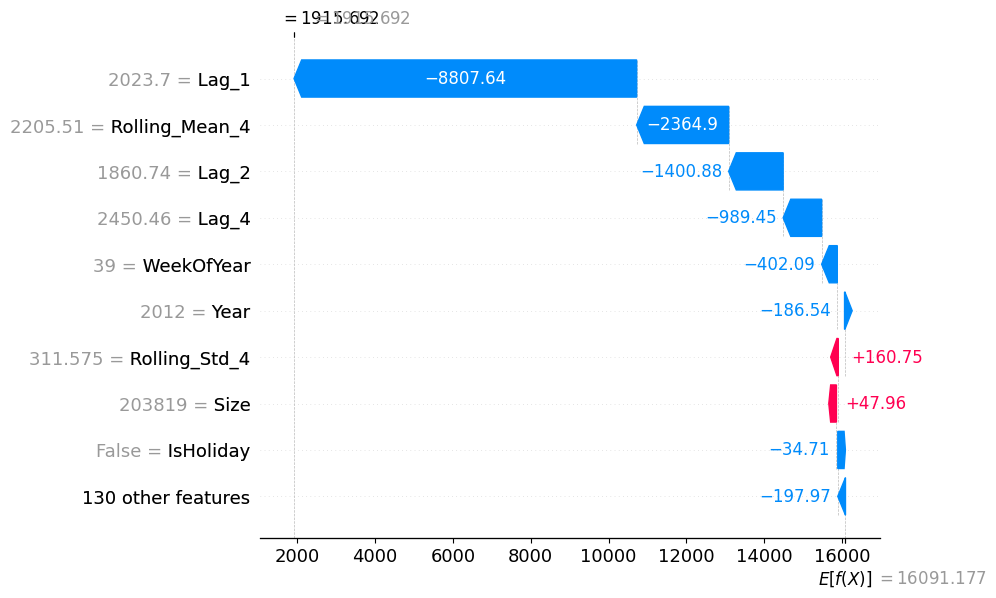

In [ ]:

# SHAP waterfall plot for one test observation

shap.plots.waterfall(
    shap_values[0],
    max_display=10
)


The waterfall plot shows that historical sales features have a strong influence on individual predictions. In this example, Lag_1, Rolling_Mean_4, Lag_2, and Lag_4 all reduce the predicted sales relative to the baseline.

In [ ]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict using the retrained XGBoost model
final_pred = best_model.predict(X_test_shap)
actual = y_test.to_numpy()

# Calculate evaluation metrics
mae = mean_absolute_error(actual, final_pred)
rmse = np.sqrt(mean_squared_error(actual, final_pred))
wape = (
    np.abs(actual - final_pred).sum()
    / np.abs(actual).sum()
) * 100
r2 = r2_score(actual, final_pred)

print("Final Model: XGBoost (B_Temporal)")
print("Actual observations:", len(actual))
print("Predictions:", len(final_pred))
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("WAPE:", round(wape, 3), "%")
print("R2:", round(r2, 4))


Final Model: XGBoost (B_Temporal)
Actual observations: 82773
Predictions: 82773
MAE: 1310.837
RMSE: 2747.137
WAPE: 8.298 %
R2: 0.9844


In [ ]:

# Review the anomaly threshold and flagged observations

error_std = error_df['Error'].std()
error_mean = error_df['Error'].mean()
error_limit = 2 * error_std

anomaly_count = (error_df['Error'].abs() > error_limit).sum()
anomaly_percent = anomaly_count / len(error_df) * 100

print("Mean prediction error:", round(error_mean, 2))
print("Standard deviation:", round(error_std, 2))
print("Threshold (+/-):", round(error_limit, 2))
print("Potential anomalies:", anomaly_count)
print("Percentage flagged:", round(anomaly_percent, 2), "%")


Mean prediction error: 296.15
Standard deviation: 2731.14
Threshold (+/-): 5462.29
Potential anomalies: 3687
Percentage flagged: 4.45 %


### Project Summary
Machine learning-based Walmart weekly sales forecasting using historical, temporal, and external features.

**Key Tasks:** EDA, feature engineering, model comparison, SHAP explainability, Store–Department error analysis, and residual-based anomaly detection.

**Best Model:** XGBoost with temporal features (WAPE: 8.298%, R²: 0.9844).

In [ ]:
print(" DATASET CHECK ")

if "train_df" in globals():
    print("Training data shape:", train_df.shape)
else:
    print("train_df: Not found")

if "test_df" in globals():
    print("Test data shape:", test_df.shape)
else:
    print("test_df: Not found")

print("\n MODEL CHECK ")

if "best_model" in globals():
    print("Model:", type(best_model).__name__)
else:
    print("best_model: Not found")

print("\n FEATURE CHECK ")

if "test_df" in globals():
    print("Test columns:")
    print(test_df.columns.tolist())

print("\n PREDICTION VARIABLES ")

for name in ["X_train", "X_test", "y_train", "y_test",
             "y_pred", "best_model", "feature_cols"]:
    if name in globals():
        print(name, ": Available")
    else:
        print(name, ": Not found")


 DATASET CHECK 
Training data shape: (325663, 30)
Test data shape: (82773, 30)

 MODEL CHECK 
Model: XGBRegressor

 FEATURE CHECK 
Test columns:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday', 'Type', 'Size', 'Year', 'Month', 'MarkDown1_Missing', 'MarkDown2_Missing', 'MarkDown3_Missing', 'MarkDown4_Missing', 'MarkDown5_Missing', 'WeekOfYear', 'Quarter', 'Lag_1', 'Lag_2', 'Lag_4', 'Rolling_Mean_4', 'Rolling_Std_4']

 PREDICTION VARIABLES 
X_train : Available
X_test : Available
y_train : Available
y_test : Available
y_pred : Not found
best_model : Available
feature_cols : Not found


In [ ]:

# Split training data into fitting and calibration sets

import numpy as np
import pandas as pd

# Use the existing training features and target
split_index = int(len(X_train) * 0.80)

X_fit = X_train.iloc[:split_index].copy()
X_cal = X_train.iloc[split_index:].copy()

y_fit = y_train.iloc[:split_index].copy()
y_cal = y_train.iloc[split_index:].copy()

print("Model fitting rows:", len(X_fit))
print("Calibration rows:", len(X_cal))

print("\nCalibration period:")
if "Date" in train_df.columns:
    print("Start:", train_df.iloc[split_index]["Date"])
    print("End:", train_df.iloc[-1]["Date"])
else:
    print("Check the date range using your original training data.")

print("\nTest rows (unchanged):", len(X_test))


Model fitting rows: 260530
Calibration rows: 65133

Calibration period:
Start: 2010-03-05 00:00:00
End: 2012-04-13 00:00:00

Test rows (unchanged): 82773


In [ ]:

# Fit XGBoost on the model-fitting data

from sklearn.base import clone

# Create a separate model with the same settings
uncertainty_model = clone(best_model)

# Train using only the fitting portion
uncertainty_model.fit(X_fit, y_fit)

print("Model training completed!")
print("Model:", type(uncertainty_model).__name__)
print("Rows used for fitting:", len(X_fit))
print("Rows reserved for calibration:", len(X_cal))


Model training completed!
Model: XGBRegressor
Rows used for fitting: 260530
Rows reserved for calibration: 65133


In [ ]:

# Calculate calibration prediction errors

from sklearn.metrics import mean_absolute_error
import numpy as np

# Predict sales on the calibration data
cal_predictions = uncertainty_model.predict(X_cal)

# Calculate absolute prediction errors
cal_errors = np.abs(np.asarray(y_cal) - cal_predictions)

print("Calibration MAE:", round(mean_absolute_error(y_cal, cal_predictions), 2))
print("Mean absolute error:", round(np.mean(cal_errors), 2))
print("Median absolute error:", round(np.median(cal_errors), 2))
print("90th percentile of absolute errors:",
      round(np.quantile(cal_errors, 0.90), 2))
print("Number of calibration observations:", len(cal_errors))


Calibration MAE: 1118.66
Mean absolute error: 1118.66
Median absolute error: 414.2
90th percentile of absolute errors: 2747.13
Number of calibration observations: 65133


In [ ]:

#  Calculate the conformal prediction interval

# Significance level: 10% for nominal 90% coverage
alpha = 0.10

# Conformal quantile with the finite-sample adjustment
n_cal = len(cal_errors)
q_index = int(np.ceil((n_cal + 1) * (1 - alpha)))

# Convert to a zero-based index and cap at the final available error
q_index = min(q_index, n_cal) - 1

conformal_quantile = np.sort(cal_errors)[q_index]

print("Target coverage:", "90%")
print("Conformal error threshold:", round(conformal_quantile, 2))

# Predict on the untouched test features
test_predictions = uncertainty_model.predict(X_test)

# Construct lower and upper bounds
lower_bound = test_predictions - conformal_quantile
upper_bound = test_predictions + conformal_quantile

print("\nExample prediction intervals:")
for i in range(5):
    print(
        f"Actual: {np.asarray(y_test)[i]:.2f} | "
        f"Predicted: {test_predictions[i]:.2f} | "
        f"Lower: {lower_bound[i]:.2f} | "
        f"Upper: {upper_bound[i]:.2f}"
    )


Target coverage: 90%
Conformal error threshold: 2747.54

Example prediction intervals:
Actual: 16976.19 | Predicted: 29560.77 | Lower: 26813.24 | Upper: 32308.31
Actual: 16347.60 | Predicted: 18168.82 | Lower: 15421.28 | Upper: 20916.36
Actual: 17147.44 | Predicted: 32758.01 | Lower: 30010.47 | Upper: 35505.54
Actual: 18164.20 | Predicted: 21416.84 | Lower: 18669.30 | Upper: 24164.38
Actual: 18517.79 | Predicted: 21931.91 | Lower: 19184.37 | Upper: 24679.44


In [ ]:

# Evaluate prediction interval reliability

actual_sales = np.asarray(y_test)

# Check whether actual sales fall inside each interval
inside_interval = (
    (actual_sales >= lower_bound) &
    (actual_sales <= upper_bound)
)

# Calculate reliability metrics
coverage = np.mean(inside_interval) * 100
mean_width = np.mean(upper_bound - lower_bound)
median_width = np.median(upper_bound - lower_bound)

print("===== FORECAST RELIABILITY =====")
print(f"Target coverage: 90.00%")
print(f"Observed test coverage: {coverage:.2f}%")
print(f"Mean interval width: {mean_width:.2f}")
print(f"Median interval width: {median_width:.2f}")

print("\n===== INTERVAL COUNTS =====")
print("Actual values inside interval:", inside_interval.sum())
print("Actual values outside interval:", (~inside_interval).sum())
print("Total test observations:", len(actual_sales))


===== FORECAST RELIABILITY =====
Target coverage: 90.00%
Observed test coverage: 85.92%
Mean interval width: 5495.07
Median interval width: 5495.07

===== INTERVAL COUNTS =====
Actual values inside interval: 71117
Actual values outside interval: 11656
Total test observations: 82773


In [ ]:

# Analyze reliability by Store and Department

reliability_df = pd.DataFrame({
    "Store": test_df["Store"].to_numpy(),
    "Dept": test_df["Dept"].to_numpy(),
    "Actual_Sales": actual_sales,
    "Predicted_Sales": test_predictions,
    "Lower_Bound": lower_bound,
    "Upper_Bound": upper_bound,
    "Inside_Interval": inside_interval
})

reliability_df["Interval_Width"] = (
    reliability_df["Upper_Bound"] - reliability_df["Lower_Bound"]
)

# Calculate metrics for each Store-Department group
group_reliability = (
    reliability_df
    .groupby(["Store", "Dept"])
    .agg(
        Observations=("Actual_Sales", "size"),
        Coverage=("Inside_Interval", "mean"),
        Mean_Interval_Width=("Interval_Width", "mean"),
        MAE=("Actual_Sales",
             lambda x: np.mean(np.abs(
                 x.to_numpy() -
                 reliability_df.loc[x.index, "Predicted_Sales"].to_numpy()
             )))
    )
    .reset_index()
)

group_reliability["Coverage"] *= 100

print("Total Store-Department groups:", len(group_reliability))

print("\nLowest-coverage groups:")
display(
    group_reliability
    .sort_values(["Coverage", "Observations"])
    .head(10)
    .round(2)
)

print("\nHighest-coverage groups:")
display(
    group_reliability
    .sort_values("Coverage", ascending=False)
    .head(10)
    .round(2)
)



Total Store-Department groups: 3138

Lowest-coverage groups:


,Store,Dept,Observations,Coverage,Mean_Interval_Width,MAE
1444,20,92,28,0.00,5495.07,12689.36
66,1,92,28,7.14,5495.07,9761.77
184,3,38,28,10.71,5495.07,8889.67
1647,23,72,28,10.71,5495.07,8842.79
1734,24,95,28,10.71,5495.07,6308.38
110,2,38,28,14.29,5495.07,6707.58
697,10,72,28,14.29,5495.07,11674.41
930,13,92,28,14.29,5495.07,8100.73
1003,14,92,28,14.29,5495.07,17850.81
1006,14,95,28,14.29,5495.07,9501.90



Highest-coverage groups:


,Store,Dept,Observations,Coverage,Mean_Interval_Width,MAE
3136,45,97,28,100.0,5495.07,442.63
2482,35,56,27,100.0,5495.07,337.72
2484,35,59,25,100.0,5495.07,170.77
2485,35,60,28,100.0,5495.07,147.43
2487,35,71,28,100.0,5495.07,1168.88
2490,35,78,1,100.0,5495.07,270.00
2492,35,80,28,100.0,5495.07,210.46
2493,35,81,28,100.0,5495.07,359.97
2495,35,83,28,100.0,5495.07,416.25
17,1,19,28,100.0,5495.07,264.11


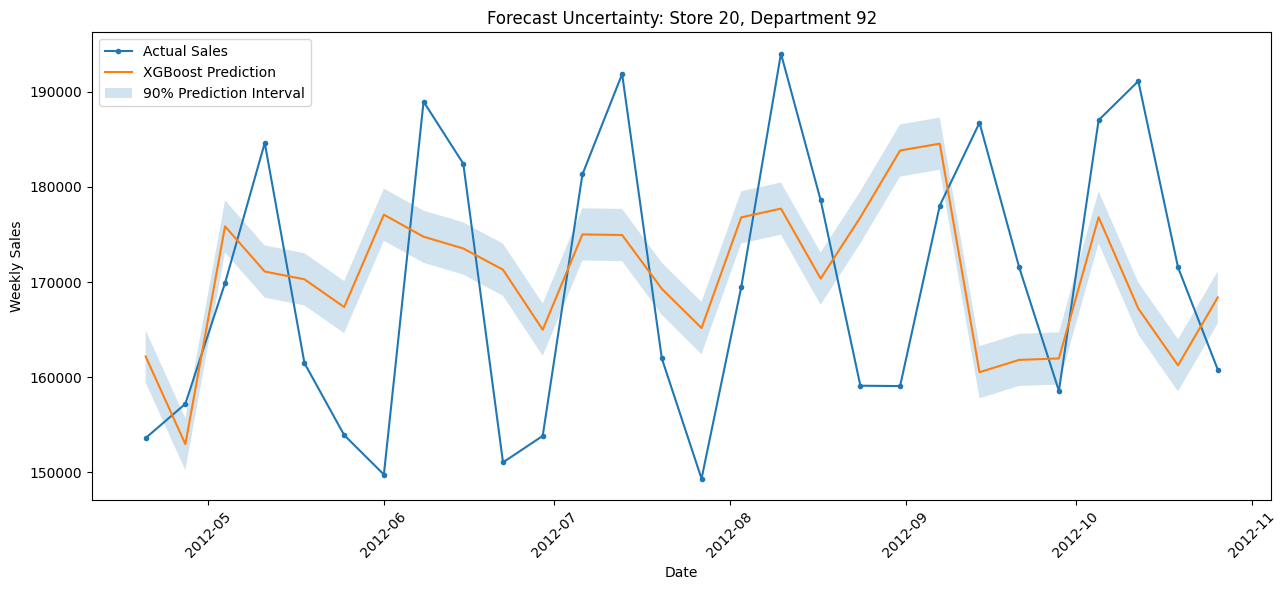

Store: 20
Department: 92
Observations: 28
Observed group coverage: 0.0 %


In [ ]:

# Cell 8: Plot actual sales, predictions, and prediction intervals

import matplotlib.pyplot as plt
import pandas as pd

# Create a plotting dataframe with dates aligned by row position
reliability_df["Date"] = pd.to_datetime(
    test_df["Date"].to_numpy()
)

# Select a Store-Department group with poor coverage
selected_store = 20
selected_dept = 92

plot_df = reliability_df[
    (reliability_df["Store"] == selected_store) &
    (reliability_df["Dept"] == selected_dept)
].copy()

# Sort chronologically
plot_df = plot_df.sort_values("Date")

# Plot results
plt.figure(figsize=(13, 6))

plt.plot(
    plot_df["Date"],
    plot_df["Actual_Sales"],
    label="Actual Sales",
    marker="o",
    markersize=3
)

plt.plot(
    plot_df["Date"],
    plot_df["Predicted_Sales"],
    label="XGBoost Prediction"
)

plt.fill_between(
    plot_df["Date"],
    plot_df["Lower_Bound"],
    plot_df["Upper_Bound"],
    alpha=0.2,
    label="90% Prediction Interval"
)

plt.title(
    f"Forecast Uncertainty: Store {selected_store}, "
    f"Department {selected_dept}"
)
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Store:", selected_store)
print("Department:", selected_dept)
print("Observations:", len(plot_df))
print(
    "Observed group coverage:",
    round(plot_df["Inside_Interval"].mean() * 100, 2),
    "%"
)


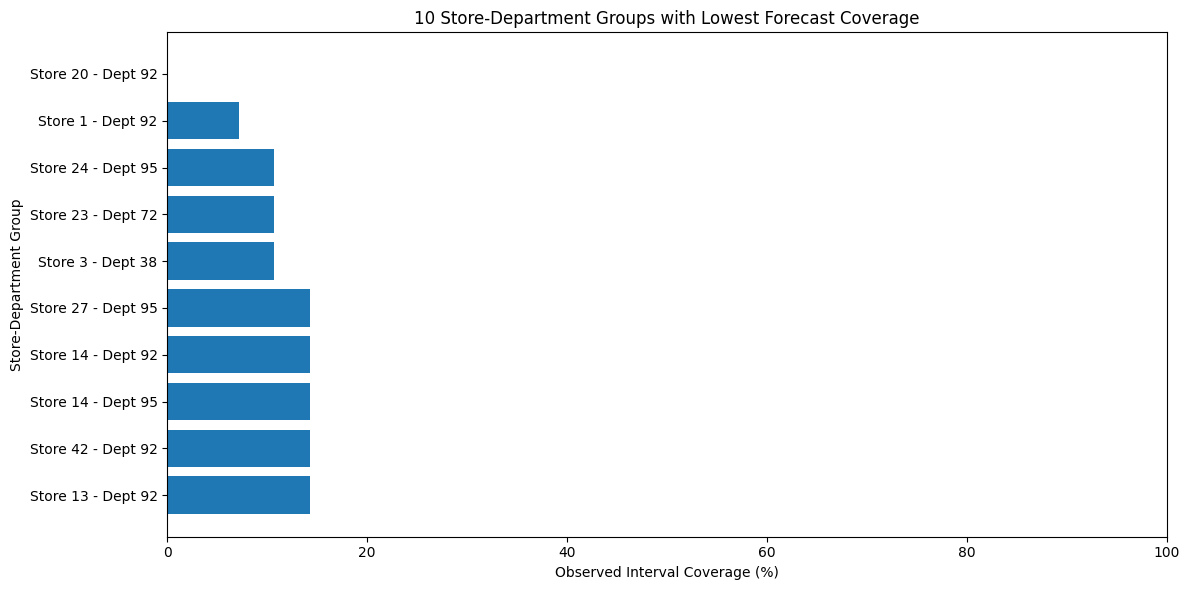

Lowest-coverage groups:


,Store,Dept,Observations,Coverage,MAE
1444,20,92,28,0.00,12689.36
66,1,92,28,7.14,9761.77
1734,24,95,28,10.71,6308.38
1647,23,72,28,10.71,8842.79
184,3,38,28,10.71,8889.67
1953,27,95,28,14.29,7781.84
1003,14,92,28,14.29,17850.81
1006,14,95,28,14.29,9501.90
2947,42,92,28,14.29,7990.59
930,13,92,28,14.29,8100.73


In [ ]:

# Compare Store-Department forecast reliability

import matplotlib.pyplot as plt

# Select 10 groups with the lowest coverage
lowest_coverage = (
    group_reliability
    .sort_values("Coverage", ascending=True)
    .head(10)
    .copy()
)

# Create labels for the chart
lowest_coverage["Group"] = (
    "Store " + lowest_coverage["Store"].astype(str)
    + " - Dept " + lowest_coverage["Dept"].astype(str)
)

# Plot coverage
plt.figure(figsize=(12, 6))

plt.barh(
    lowest_coverage["Group"],
    lowest_coverage["Coverage"]
)

plt.xlabel("Observed Interval Coverage (%)")
plt.ylabel("Store-Department Group")
plt.title("10 Store-Department Groups with Lowest Forecast Coverage")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Lowest-coverage groups:")
display(
    lowest_coverage[
        ["Store", "Dept", "Observations", "Coverage", "MAE"]
    ].round(2)
)
